<a href="https://colab.research.google.com/github/taiKip/python-llm-learning/blob/main/COMP6012_Assignment2_Notebook_Beginner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP6012 — Assignment 2 (Module 1)
## Evaluation of LLM Models for Text Classification and Generation
### 🟢 Beginner-friendly version

**Name:** _(fill in)_
**Student ID:** _(fill in)_

**How to use this notebook:**
- Run each cell **in order**, from top to bottom (click the ▶️ button on the left of each cell, or press `Shift+Enter`).
- Cells with `# Step` comments are the important ones — read the comment before running.
- If something errors, just re-run from the top — don't panic, this happens to everyone.
- This notebook uses **small, fast models** and **small samples** of data so it runs quickly for free
  on Colab. That's completely fine for this assignment — the brief explicitly allows down-sampling.

**Before you start:** go to `Runtime → Change runtime type → T4 GPU`, then click Save. This makes
the models run much faster.


## Step 1: Install the tools we need

We only need to run this once. `transformers` gives us pretrained LLMs, `datasets` lets us load the
Yelp and CNN/DailyMail data, and `evaluate` gives us ready-made scoring functions.


In [1]:
!pip install -q transformers datasets evaluate rouge_score scikit-learn pandas matplotlib
print("Done installing!")


Done installing!


In [2]:
# Step 2: Import everything and set a "seed" so our random sampling is reproducible
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

device = 0 if torch.cuda.is_available() else -1   # 0 = use GPU, -1 = use CPU
print("GPU available:", torch.cuda.is_available())


GPU available: True


## Part A: Text Classification (Yelp Reviews)

**The task:** given a restaurant/business review, predict how many stars (1–5) it got.

We'll load the Yelp dataset, take a small sample of it (to keep things fast), and try two different
pretrained models on it.


### Step 3: Load the Yelp dataset

This downloads the dataset from Hugging Face. It might take a minute the first time.


In [3]:
yelp = load_dataset("Yelp/yelp_review_full")

# Let's look at one example so we understand the data
print(yelp["test"][0])
# "label" is 0-4, where 0 = 1 star and 4 = 5 stars


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{'label': 0, 'text': 'I got \'new\' tires from them and within two weeks got a flat. I took my car to a local mechanic to see if i could get the hole patched, but they said the reason I had a flat was because the previous patch had blown - WAIT, WHAT? I just got the tire and never needed to have it patched? This was supposed to be a new tire. \\nI took the tire over to Flynn\'s and they told me that someone punctured my tire, then tried to patch it. So there are resentful tire slashers? I find that very unlikely. After arguing with the guy and telling him that his logic was far fetched he said he\'d give me a new tire \\"this time\\". \\nI will never go back to Flynn\'s b/c of the way this guy treated me and the simple fact that they gave me a used tire!'}


### Step 4: Take a small, balanced sample

The full test set has 50,000 reviews — way more than we need and too slow to run on a free GPU.
We'll take a small sample instead, making sure we get an equal number of 1-star, 2-star, 3-star,
4-star, and 5-star reviews (this is called "stratified sampling").


In [4]:
SAMPLES_PER_STAR = 20   # 20 reviews per star rating = 100 reviews total. Increase later if you have time.

def get_balanced_sample(dataset_split, n_per_class, seed):
    df = dataset_split.to_pandas()
    sample = df.groupby("label", group_keys=False).apply(
        lambda x: x.sample(n=n_per_class, random_state=seed)
    )
    return sample.sample(frac=1, random_state=seed).reset_index(drop=True)  # shuffle rows

yelp_sample = get_balanced_sample(yelp["test"], SAMPLES_PER_STAR, SEED)
print("Sample size:", len(yelp_sample))
yelp_sample.head()


Sample size: 100


/tmp/ipykernel_8160/1943259619.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = df.groupby("label", group_keys=False).apply(


,label,text
0,4,fantastic! what air travel should be. a quick...
1,2,The sweet crepes are great. From classic simpl...
2,3,My husband and I loved this place. The staff w...
3,2,"Pretty good for kids, average to below average..."
4,2,We came to this place since Mr.Mama's was very...


### Step 5: Load two pretrained models

We'll compare:
- **Model 1 — a sentiment-tuned BERT model.** This model was already trained specifically to predict
  1–5 star ratings from review text, so it should do quite well.
- **Model 2 — zero-shot classification with BART.** This model was *not* trained for star ratings at
  all. Instead, we just ask it "which of these 5 labels fits best?" This is a fun comparison because
  it shows the difference between a model trained for the exact task vs. a general-purpose model.

The first time you run this, it will download the models (a few hundred MB each) — this can take a
minute or two.


In [5]:
from transformers import pipeline

# Model 1: trained specifically to output 1-5 star predictions
model1 = pipeline(
    "text-classification",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=device,
    truncation=True,
)

# Quick test on one review
print(model1("The food was amazing and the staff were so friendly!"))


Device set to use cuda:0


[{'label': '5 stars', 'score': 0.8164605498313904}]


In [6]:
# Model 2: general-purpose model, told to choose between our 5 labels
model2 = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=device,
)

star_labels = ["1 star", "2 stars", "3 stars", "4 stars", "5 stars"]

# Quick test
print(model2("The food was amazing and the staff were so friendly!", star_labels))


Device set to use cuda:0


{'sequence': 'The food was amazing and the staff were so friendly!', 'labels': ['2 stars', '3 stars', '5 stars', '4 stars', '1 star'], 'scores': [0.24906443059444427, 0.23859834671020508, 0.2226385772228241, 0.21548599004745483, 0.07421261072158813]}


### Step 6: Run both models on our sample of reviews

This is the slow part — we're asking each model to read every review in our sample and guess the
star rating. With 100 reviews and a GPU this should take under a minute per model.


In [7]:
def predict_with_model1(review_texts):
    predictions = []
    for review in review_texts:
        result = model1(review[:512])[0]          # only look at first 512 characters (models have a length limit)
        stars = int(result["label"].split()[0])    # result looks like {'label': '4 stars', ...}
        predictions.append(stars)
    return predictions

def predict_with_model2(review_texts):
    predictions = []
    for review in review_texts:
        result = model2(review[:512], star_labels)
        top_label = result["labels"][0]             # the model's best guess, e.g. "4 stars"
        predictions.append(int(top_label.split()[0]))
    return predictions

reviews = yelp_sample["text"].tolist()
true_stars = (yelp_sample["label"] + 1).tolist()     # convert 0-4 label into 1-5 stars

print("Running Model 1...")
model1_predictions = predict_with_model1(reviews)

print("Running Model 2 (this one is slower)...")
model2_predictions = predict_with_model2(reviews)

print("Done!")


Running Model 1...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Running Model 2 (this one is slower)...
Done!


### Step 7: Score the models

We'll use two simple, standard metrics:
- **Accuracy**: what % of reviews did the model get exactly right?
- **Macro-F1**: a balanced score across all 5 star classes (better than accuracy alone if some
  classes are harder than others).


In [8]:
from sklearn.metrics import accuracy_score, f1_score

def score_model(true_values, predicted_values, model_name):
    acc = accuracy_score(true_values, predicted_values)
    f1 = f1_score(true_values, predicted_values, average="macro")
    print(f"{model_name}: accuracy = {acc:.2f}, macro-F1 = {f1:.2f}")
    return {"model": model_name, "accuracy": acc, "macro_f1": f1}

score1 = score_model(true_stars, model1_predictions, "Sentiment BERT")
score2 = score_model(true_stars, model2_predictions, "Zero-shot BART")

classification_results = pd.DataFrame([score1, score2])
classification_results


Sentiment BERT: accuracy = 0.63, macro-F1 = 0.63
Zero-shot BART: accuracy = 0.34, macro-F1 = 0.30


,model,accuracy,macro_f1
0,Sentiment BERT,0.63,0.625815
1,Zero-shot BART,0.34,0.303148


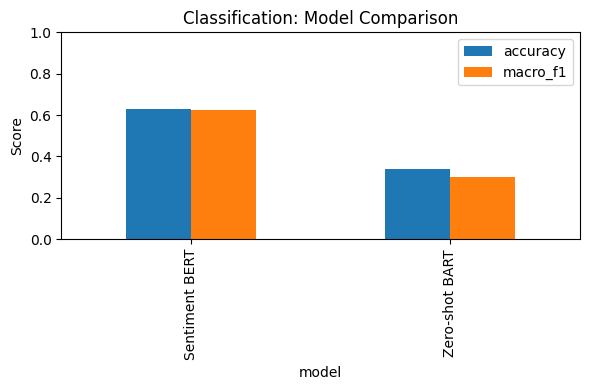

In [9]:
# A simple bar chart comparing the two models -- use this in your report!
classification_results.set_index("model")[["accuracy", "macro_f1"]].plot(kind="bar", figsize=(6,4))
plt.title("Classification: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("classification_comparison.png", dpi=150)
plt.show()


### Step 8 (bonus): A simple fairness check

Do the models do better on some star ratings than others? For example, models often struggle to
tell 3-star and 4-star reviews apart, because the language is more similar. Let's check.


            model1_correct  model2_correct
true_stars                                
1                     0.75            0.85
2                     0.55            0.20
3                     0.40            0.15
4                     0.65            0.10
5                     0.80            0.40


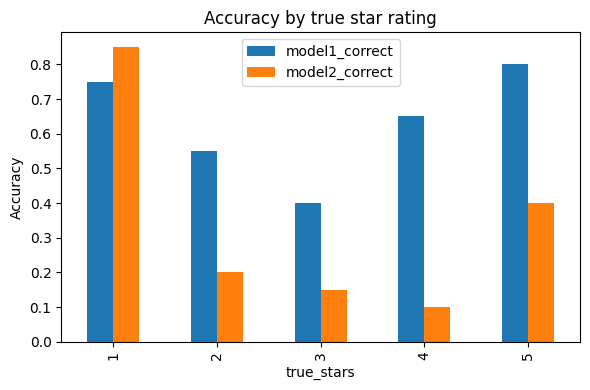

In [10]:
results_table = pd.DataFrame({
    "true_stars": true_stars,
    "model1_prediction": model1_predictions,
    "model2_prediction": model2_predictions,
})
results_table["model1_correct"] = results_table["true_stars"] == results_table["model1_prediction"]
results_table["model2_correct"] = results_table["true_stars"] == results_table["model2_prediction"]

accuracy_per_star = results_table.groupby("true_stars")[["model1_correct", "model2_correct"]].mean()
print(accuracy_per_star)

accuracy_per_star.plot(kind="bar", figsize=(6,4))
plt.title("Accuracy by true star rating")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.savefig("accuracy_by_star.png", dpi=150)
plt.show()


## Part B: Text Generation / Summarization (CNN/DailyMail)

**The task:** given a news article, generate a short summary of it.

Same approach: load the data, take a small sample, try two models, score them.


### Step 9: Load the CNN/DailyMail dataset and take a small sample

In [11]:
cnn_dailymail = load_dataset("abisee/cnn_dailymail", "3.0.0")

# Look at one example
print("ARTICLE (first 500 characters):")
print(cnn_dailymail["test"][0]["article"][:500])
print("\nHUMAN-WRITTEN SUMMARY:")
print(cnn_dailymail["test"][0]["highlights"])


ARTICLE (first 500 characters):
(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, includin

HUMAN-WRITTEN SUMMARY:
Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis .


In [12]:
N_ARTICLES = 20  # keep this small at first! summarization is slower than classification. Increase later.

news_sample = cnn_dailymail["test"].shuffle(seed=SEED).select(range(N_ARTICLES))
articles = news_sample["article"]
reference_summaries = news_sample["highlights"]    # the "correct answer" summaries written by humans
print(f"Loaded {len(articles)} articles")


Loaded 20 articles


### Step 10: Load two summarization models

- **BART-large-CNN**: pretrained specifically for summarizing news articles like these — should do well.
- **T5-small**: a smaller, general-purpose text-to-text model. We tell it what to do by adding the
  word `"summarize:"` in front of the text.


In [13]:
summarizer1 = pipeline("text-generation", model="facebook/bart-large-cnn", device=device)
summarizer2 = pipeline("text-generation", model="t5-small", device=device)

# Quick test on one article
test_article = articles[0]
print("BART summary:", summarizer1(test_article, max_length=100, min_length=20, truncation=True))
print("\nT5 summary:", summarizer2("summarize: " + test_article, max_length=100, min_length=20, truncation=True))

Device set to use cuda:0


model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0
The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'LlamaForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'Data2VecTextForCausalLM', 'DbrxForCausalLM', 'DeepseekV2ForCausalLM', 'DeepseekV3ForCausalLM', 'DiffLlamaForCausalLM', 'DogeForCausalLM', 'Dots1ForCausalLM', 'ElectraForCausalLM', 'Emu3ForCausalLM', 'ErnieForCausalLM', 'Ernie4_5ForCausalLM', 'Ernie4_5_MoeForCausalLM', 'Exaone4ForCausalLM', 'FalconForCausalLM', 'FalconH1ForCausalLM', 'FalconMambaForCausalLM', 'FlexOl

BART summary: [{'generated_text': '(CNN) I see signs of a revolution everywhere. I see it in the op-ed pages of the newspapers, and on the state ballots in nearly half the country. I see it in politicians who once preferred to play it safe with this explosive issue but are now willing to stake their political futures on it. I see the revolution in the eyes of sterling scientists, previously reluctant to dip a toe into this heavily stigmatized world, who are diving in head first. I see it in the new surgeon general who cites data showing just how helpful it can be. I see a revolution in the attitudes of everyday Americans. For the first time a majority, 53%, favor its legalization, with 77% supporting it for medical purposes. Support for legalization has risen 11 points in the past few years alone. In 1969, the first time Pew asked the question about legalization, only 12% of the nation was in favor. I see a revolution that is burning white hot among young people, but also shows up amon

### Step 11: Generate summaries for our whole sample

This can take a couple of minutes — summarization is slower than classification because the model
has to generate text word-by-word.


In [16]:
def generate_summaries(summarizer, texts, prefix=""):
    summaries = []
    for text in texts:
        result = summarizer(prefix + text, max_length=100, min_length=20, truncation=True)
        summaries.append(result[0]["generated_text"])
    return summaries

print("Generating BART summaries...")
bart_summaries = generate_summaries(summarizer1, articles)

print("Generating T5 summaries...")
t5_summaries = generate_summaries(summarizer2, articles, prefix="summarize: ")

print("Done! Example:")
print("Reference: ", reference_summaries[0])
print("BART:      ", bart_summaries[0])
print("T5:        ", t5_summaries[0])

Generating BART summaries...


Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating T5 summaries...


Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Done! Example:
Reference:  CNN's Dr. Sanjay Gupta says we should legalize medical marijuana now .
He says he knows how easy it is do nothing "because I did nothing for too long"
BART:       (CNN) I see signs of a revolution everywhere. I see it in the op-ed pages of the newspapers, and on the state ballots in nearly half the country. I see it in politicians who once preferred to play it safe with this explosive issue but are now willing to stake their political futures on it. I see the revolution in the eyes of sterling scientists, previously reluctant to dip a toe into this heavily stigmatized world, who are diving in head first. I see it in the new surgeon general who cites data showing just how helpful it can be. I see a revolution in the attitudes of everyday Americans. For the first time a majority, 53%, favor its legalization, with 77% supporting it for medical purposes. Support for legalization has risen 11 points in the past few years alone. In 1969, the first time Pew asked th

### Step 12: Score the summaries with ROUGE


In [17]:
import evaluate
rouge = evaluate.load("rouge")

bart_scores = rouge.compute(predictions=bart_summaries, references=reference_summaries)
t5_scores = rouge.compute(predictions=t5_summaries, references=reference_summaries)

print("BART scores:", bart_scores)
print("T5 scores:  ", t5_scores)

generation_results = pd.DataFrame([
    {"model": "BART-large-CNN", **bart_scores},
    {"model": "T5-small", **t5_scores},
])
generation_results


BART scores: {'rouge1': np.float64(0.12679199415562803), 'rouge2': np.float64(0.06596840573795312), 'rougeL': np.float64(0.09175833422437604), 'rougeLsum': np.float64(0.10922652281991259)}
T5 scores:   {'rouge1': np.float64(0.12657556925850988), 'rouge2': np.float64(0.06584725967460445), 'rougeL': np.float64(0.09160133491077782), 'rougeLsum': np.float64(0.10904630205485659)}


,model,rouge1,rouge2,rougeL,rougeLsum
0,BART-large-CNN,0.126792,0.065968,0.091758,0.109227
1,T5-small,0.126576,0.065847,0.091601,0.109046


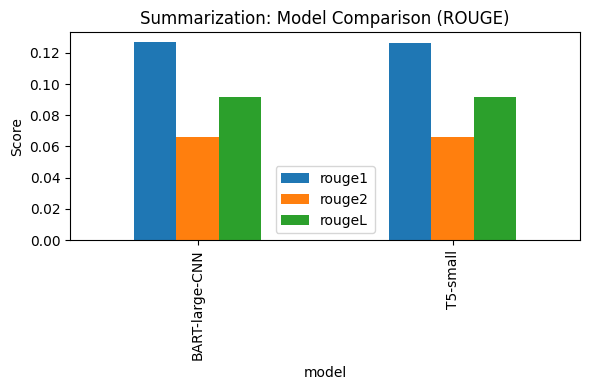

In [18]:
generation_results.set_index("model")[["rouge1", "rouge2", "rougeL"]].plot(kind="bar", figsize=(6,4))
plt.title("Summarization: Model Comparison (ROUGE)")
plt.ylabel("Score")
plt.tight_layout()
plt.savefig("generation_comparison.png", dpi=150)
plt.show()


## Step 13: Save your results

This saves your tables as CSV files and your charts as PNG images, both of which you can drop
straight into your Word report.


In [19]:
classification_results.to_csv("classification_results.csv", index=False)
generation_results.to_csv("generation_results.csv", index=False)
accuracy_per_star.to_csv("accuracy_by_star.csv")

print("Saved CSVs: classification_results.csv, generation_results.csv, accuracy_by_star.csv")
print("Saved charts: classification_comparison.png, accuracy_by_star.png, generation_comparison.png")
print("\nGo to the folder icon on the left sidebar in Colab to download these files.")


Saved CSVs: classification_results.csv, generation_results.csv, accuracy_by_star.csv
Saved charts: classification_comparison.png, accuracy_by_star.png, generation_comparison.png

Go to the folder icon on the left sidebar in Colab to download these files.


## What to do next (checklist for your report)

- [ ] **Introduction**: explain what LLMs are + a diagram + a simple example (this notebook doesn't
      cover this part — it's conceptual writing based on Module 1 lecture content).
- [ ] **Task Design**: describe Steps 3–5 (Yelp) and Steps 9–10 (CNN/DailyMail) in your own words —
      what data you used, how you sampled it, which models you picked and why.
- [ ] **Metrics**: explain accuracy/macro-F1 (Step 7) and ROUGE (Step 12) — why they fit each task.
- [ ] **Results & Analysis**: paste in `classification_comparison.png`, `accuracy_by_star.png`, and
      `generation_comparison.png`. Write 2–3 sentences per chart about what it shows.
- [ ] **Reflection**: once you've seen your actual numbers, write about what surprised you (e.g. was
      zero-shot much worse? did T5-small struggle compared to BART?), what the limitations were
      (small sample size, models sometimes truncating long text), and what you'd do differently
      with more time/compute.

**Tip:** once everything runs correctly with small numbers, try increasing `SAMPLES_PER_STAR` and
`N_ARTICLES` a bit (e.g. double them) and re-run, so your final results are based on slightly more
data. Don't go too high on the free Colab GPU or it may time out.
